In [1]:
import datetime
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from dataloader import get_participants_data, get_participants_demographics
from stats import two_sample_test, pairwise_test
import pingouin as pg
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'''\usepackage{libertine}\usepackage{fontawesome5}\usepackage{xcolor}'''
plt.rcParams['ps.usedistiller'] = 'xpdf'
sns.set_theme(style='ticks')
from statannotations.Annotator import Annotator
import scipy
from scipy import signal
import cv2

In [2]:
interfaces = ['pointwise', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie', 'listwise-ranking']
df_begins = pd.DataFrame()
df_all = pd.DataFrame()
df_finishs = pd.DataFrame()
batches = [1]

for batch in batches:
    for interface in interfaces:
        df_begin, df_iter, df_finish = get_participants_data('image', batch, interface)
        df_begin['interface'] = interface
        df_iter['interface'] = interface
        df_finish['interface'] = interface
        df_begins = pd.concat([df_begins, df_begin], ignore_index=True)
        df_all = pd.concat([df_all, df_iter], ignore_index=True)
        df_finishs = pd.concat([df_finishs, df_finish], ignore_index=True)

print(df_all.columns)

Index(['userID', 'studyID', 'sessionID', 'taskID', 'feedbackID', 'groundTruth',
       'iteration', 'completeIteration', 'incompleteIteration', 'rating',
       'skip', 'parameters', 'timePresent', 'timeLastRating', 'timeSubmit',
       'comment', 'stop', 'options', 'interface', 'selection'],
      dtype='object')


In [3]:
df_progress = df_all[['userID', 'taskID', 'interface', 'iteration', 'rating', 'skip', 'parameters', 'options']]
for idx, row in df_progress.iterrows():
    df_progress.loc[idx, 'ground_truth'] = 'domain/image/1/' + row.interface + '/tasks/' + row.taskID + '.jpg'
df_progress

,userID,taskID,interface,iteration,rating,skip,parameters,options,ground_truth
0,P202,3,pointwise,1,6,False,"[{'brightness': 0.48496636748313904, 'contrast...",[domain/image/1/pointwise/608ddb1cc919e2385b98...,domain/image/1/pointwise/tasks/3.jpg
1,P202,3,pointwise,2,75,False,"[{'brightness': 0.537386417388916, 'contrast':...",[domain/image/1/pointwise/608ddb1cc919e2385b98...,domain/image/1/pointwise/tasks/3.jpg
2,P202,3,pointwise,3,27,False,"[{'brightness': 0.20025870203971863, 'contrast...",[domain/image/1/pointwise/608ddb1cc919e2385b98...,domain/image/1/pointwise/tasks/3.jpg
3,P202,3,pointwise,4,0,False,"[{'brightness': 0.877985417842865, 'contrast':...",[domain/image/1/pointwise/608ddb1cc919e2385b98...,domain/image/1/pointwise/tasks/3.jpg
4,P202,3,pointwise,5,42,False,"[{'brightness': 0.4819245934486389, 'contrast'...",[domain/image/1/pointwise/608ddb1cc919e2385b98...,domain/image/1/pointwise/tasks/3.jpg
...,...,...,...,...,...,...,...,...,...
5042,P149,2,listwise-ranking,2,"[{'id': 0, 'rating': 'Excellent', 'timestamp':...",False,"[{'brightness': 0.571182370185852, 'contrast':...",[domain/image/1/listwise-ranking/60b63cc430b27...,domain/image/1/listwise-ranking/tasks/2.jpg
5043,P149,2,listwise-ranking,3,"[{'id': 1, 'rating': 'Fair', 'timestamp': 1670...",False,"[{'brightness': 0.629599392414093, 'contrast':...",[domain/image/1/listwise-ranking/60b63cc430b27...,domain/image/1/listwise-ranking/tasks/2.jpg
5044,P149,2,listwise-ranking,4,"[{'id': 0, 'rating': 'I don't know', 'timestam...",False,"[{'brightness': 0.4798765480518341, 'contrast'...",[domain/image/1/listwise-ranking/60b63cc430b27...,domain/image/1/listwise-ranking/tasks/2.jpg
5045,P149,2,listwise-ranking,5,"[{'id': 2, 'rating': 'Excellent', 'timestamp':...",False,"[{'brightness': 0.2839641869068146, 'contrast'...",[domain/image/1/listwise-ranking/60b63cc430b27...,domain/image/1/listwise-ranking/tasks/2.jpg


In [7]:
def infer_ranking(rating):
    ratings = ['', '', '', '']
    for op in rating:
        ratings[op['id']] = op['rating']
    rating_map = {
        'Excellent': 5,
        'Good': 4,
        'Fair': 3,
        'Poor': 2,
        'Terrible': 1,
        "I don't know": -1,
    }
    ranking = [rating_map[r] for r in ratings]
    return ranking

def compute_image_quality(df, redo=False):
    if not redo:
        return pd.read_csv('processed/quality_image.csv')

    df_quality = df[['userID', 'taskID', 'interface', 'iteration', 'options', 'ground_truth']]
    df_quality['brightness'] = 0
    df_quality['contrast'] = 0
    df_quality['saturation'] = 0
    df_quality['temperature'] = 0
    df_quality['tint'] = 0

    for idx, row in df_quality.iterrows():
        count  = 0
        arr_brightness = []
        arr_contrast = []
        arr_saturation = []
        arr_temperature = []
        arr_tint = []
        for option in row.options:
            option = option.replace(f'data/image-listwise-ranking/', f'domain/image/')
            src, dst = row.ground_truth, option
            print(src, dst)
            # compute difference of brightness
            src = cv2.imread(src)
            dst = cv2.imread(dst)
            src1 = cv2.cvtColor(src, cv2.COLOR_BGR2HSV)
            dst1 = cv2.cvtColor(dst, cv2.COLOR_BGR2HSV)
            src1 = src1.astype('float32')
            dst1 = dst1.astype('float32')
            src_h, src_s, src_v = cv2.split(src1)
            dst_h, dst_s, dst_v = cv2.split(dst1)
            arr_brightness.append(np.mean((src_v - dst_v) * (src_v - dst_v)))
            arr_contrast.append(np.mean((src_s - dst_s) * (src_s - dst_s)))
            arr_saturation.append(np.mean((src_h - dst_h) * (src_h - dst_h)))

            src2 = cv2.cvtColor(src, cv2.COLOR_BGR2YUV)
            dst2 = cv2.cvtColor(dst, cv2.COLOR_BGR2YUV)
            src2 = src2.astype('float32')
            dst2 = dst2.astype('float32')
            src_y, src_u, src_v = cv2.split(src2)
            dst_y, dst_u, dst_v = cv2.split(dst2)
            arr_temperature.append(np.mean((src_v - dst_v) * (src_v - dst_v)))
            arr_tint.append(np.mean((src_u - dst_u) * (src_u - dst_u)))
            count += 1

        df_quality.loc[idx, 'brightness'] = str(arr_brightness)
        df_quality.loc[idx, 'contrast'] = str(arr_contrast)
        df_quality.loc[idx, 'saturation'] = str(arr_saturation)
        df_quality.loc[idx, 'temperature'] = str(arr_temperature)
        df_quality.loc[idx, 'tint'] = str(arr_tint)

        df_quality[['userID', 'taskID', 'interface', 'iteration', 'brightness', 'contrast', 'saturation', 'temperature', 'tint']].to_csv('processed/quality_image.csv', index=False)
    return df_quality

df_quality = compute_image_quality(df_progress, redo=True)

domain/image/1/pointwise/tasks/3.jpg domain/image/1/pointwise/P202-S202/options/ac2db37a-74ee-11ed-ab7c-a85e4557a9b6/aba44531-74ee-11ed-ab7c-a85e4557a9b6.jpg
domain/image/1/pointwise/tasks/3.jpg domain/image/1/pointwise/P202-S202/options/d9f8b0a9-74ee-11ed-ab7c-a85e4557a9b6/d9705839-74ee-11ed-ab7c-a85e4557a9b6.jpg
domain/image/1/pointwise/tasks/3.jpg domain/image/1/pointwise/P202-S202/options/70bab248-74ef-11ed-ab7c-a85e4557a9b6/70272002-74ef-11ed-ab7c-a85e4557a9b6.jpg
domain/image/1/pointwise/tasks/3.jpg domain/image/1/pointwise/P202-S202/options/ad72a240-74ef-11ed-ab7c-a85e4557a9b6/aceceb25-74ef-11ed-ab7c-a85e4557a9b6.jpg
domain/image/1/pointwise/tasks/3.jpg domain/image/1/pointwise/P202-S202/options/e33b4bb2-74ef-11ed-ab7c-a85e4557a9b6/e28027ad-74ef-11ed-ab7c-a85e4557a9b6.jpg
domain/image/1/pointwise/tasks/3.jpg domain/image/1/pointwise/P202-S202/options/14014fb4-74f0-11ed-ab7c-a85e4557a9b6/133a2abe-74f0-11ed-ab7c-a85e4557a9b6.jpg
domain/image/1/pointwise/tasks/3.jpg domain/image/1/

In [5]:
df_quality

,userID,taskID,interface,iteration,brightness,contrast,saturation,temperature,tint
0,P202,3,pointwise,1,[71.07431],[61.41595],[54.273857],[-13.108037],[-3.4818985]
1,P202,3,pointwise,2,[0.41964436],[14.559564],[10.217255],[-0.36956462],[2.1253092]
2,P202,3,pointwise,3,[53.238026],[-126.60892],[29.242851],[-15.077848],[5.5986075]
3,P202,3,pointwise,4,[-73.70928],[31.889921],[10.174063],[-22.745468],[4.272781]
4,P202,3,pointwise,5,[-11.421942],[28.623396],[6.557269],[0.7245516],[0.98306316]
...,...,...,...,...,...,...,...,...,...
4877,P149,2,listwise-ranking,2,"[-4.691031, 100.674484, -6.5005894, 91.32302]","[26.403822, -13.735132, -19.149782, -97.20164]","[-7.496203, 26.439457, -12.733071, 27.567373]","[-7.99097, -0.5541166, 7.937897, 18.502478]","[-3.900925, -0.9711007, -8.226393, 4.502668]"
4878,P149,2,listwise-ranking,3,"[40.617954, 13.224469, 7.6062565, 9.433438]","[6.8913918, -16.588829, 21.685963, 52.13149]","[5.249687, 11.074553, 20.869026, -21.805267]","[-14.405109, -19.009838, -13.566413, -11.417916]","[0.46929038, 7.31781, 6.451582, -5.353307]"
4879,P149,2,listwise-ranking,4,"[35.961727, 46.51069, 64.61875, -7.0345]","[34.441555, 20.928572, -75.09062, -119.60789]","[-22.063828, -3.242653, 36.505825, 9.626967]","[-7.701961, -8.835333, 27.787601, 36.09954]","[-7.2134156, -2.3652086, 16.840239, 21.391111]"
4880,P149,2,listwise-ranking,5,"[61.3297, 122.50658, 31.979553, 63.971073]","[-25.960836, 1.2428145, -37.32593, -61.329395]","[25.603199, 40.928368, 9.11728, 6.615033]","[10.03254, -3.9832528, -4.754668, 8.019523]","[2.3413074, -1.1475085, 6.539282, 2.1924691]"


In [6]:
# df_quality.ranking.apply(lambda x: eval(x))
df_quality.brightness.apply(lambda x: eval(x))
df_quality.contrast.apply(lambda x: eval(x))
df_quality.saturation.apply(lambda x: eval(x))
df_quality.temperature.apply(lambda x: eval(x))
df_quality.tint.apply(lambda x: eval(x))
df_quality

,userID,taskID,interface,iteration,brightness,contrast,saturation,temperature,tint
0,P202,3,pointwise,1,[71.07431],[61.41595],[54.273857],[-13.108037],[-3.4818985]
1,P202,3,pointwise,2,[0.41964436],[14.559564],[10.217255],[-0.36956462],[2.1253092]
2,P202,3,pointwise,3,[53.238026],[-126.60892],[29.242851],[-15.077848],[5.5986075]
3,P202,3,pointwise,4,[-73.70928],[31.889921],[10.174063],[-22.745468],[4.272781]
4,P202,3,pointwise,5,[-11.421942],[28.623396],[6.557269],[0.7245516],[0.98306316]
...,...,...,...,...,...,...,...,...,...
4877,P149,2,listwise-ranking,2,"[-4.691031, 100.674484, -6.5005894, 91.32302]","[26.403822, -13.735132, -19.149782, -97.20164]","[-7.496203, 26.439457, -12.733071, 27.567373]","[-7.99097, -0.5541166, 7.937897, 18.502478]","[-3.900925, -0.9711007, -8.226393, 4.502668]"
4878,P149,2,listwise-ranking,3,"[40.617954, 13.224469, 7.6062565, 9.433438]","[6.8913918, -16.588829, 21.685963, 52.13149]","[5.249687, 11.074553, 20.869026, -21.805267]","[-14.405109, -19.009838, -13.566413, -11.417916]","[0.46929038, 7.31781, 6.451582, -5.353307]"
4879,P149,2,listwise-ranking,4,"[35.961727, 46.51069, 64.61875, -7.0345]","[34.441555, 20.928572, -75.09062, -119.60789]","[-22.063828, -3.242653, 36.505825, 9.626967]","[-7.701961, -8.835333, 27.787601, 36.09954]","[-7.2134156, -2.3652086, 16.840239, 21.391111]"
4880,P149,2,listwise-ranking,5,"[61.3297, 122.50658, 31.979553, 63.971073]","[-25.960836, 1.2428145, -37.32593, -61.329395]","[25.603199, 40.928368, 9.11728, 6.615033]","[10.03254, -3.9832528, -4.754668, 8.019523]","[2.3413074, -1.1475085, 6.539282, 2.1924691]"


In [7]:
for idx, row in df_quality.iterrows():
    df_quality.loc[idx, 'brightness'] = np.mean(eval(row['brightness']))
    df_quality.loc[idx, 'contrast'] = np.mean(eval(row['contrast']))
    df_quality.loc[idx, 'saturation'] = np.mean(eval(row['saturation']))
    df_quality.loc[idx, 'temperature'] = np.mean(eval(row['temperature']))
    df_quality.loc[idx, 'tint'] = np.mean(eval(row['tint']))

df_quality_temp = df_quality.groupby(['userID', 'taskID', 'interface']).agg({
    'brightness': lambda x: list(x), 
    'contrast': lambda x: list(x), 
    'saturation': lambda x: list(x), 
    'temperature': lambda x: list(x), 
    'tint':   lambda x: list(x)}).reset_index()
df_quality_progress = pd.DataFrame()
for idx, row in df_quality_temp.iterrows():
    brig = scipy.signal.resample(row['brightness'], 20)
    cont = scipy.signal.resample(row['contrast'], 20)
    satu = scipy.signal.resample(row['saturation'], 20)
    temp = scipy.signal.resample(row['temperature'], 20)
    tint = scipy.signal.resample(row['tint'], 20)

    for i, v in enumerate(brig):
        df_quality_progress = df_quality_progress.append({
            'userID': row['userID'], 'taskID': row['taskID'], 'interface': row.interface, 'iteration': i,
            'brightness': brig[i], 'contrast': cont[i], 'saturation': satu[i], 'temperature': temp[i], 'tint': tint[i]
        }, ignore_index=True)

df_quality_progress

,userID,taskID,interface,iteration,brightness,contrast,saturation,temperature,tint
0,P042,1,listwise-rating,0,0.226037,-48.983027,18.633245,-9.894252,-4.980639
1,P042,1,listwise-rating,1,4.961788,-50.137972,21.217918,-8.500183,-4.230520
2,P042,1,listwise-rating,2,18.907722,-49.359229,29.061398,-5.826508,-1.384902
3,P042,1,listwise-rating,3,30.797494,-50.952732,36.442556,-1.544732,0.938279
4,P042,1,listwise-rating,4,31.410836,-57.294944,38.546213,3.816834,0.829787
...,...,...,...,...,...,...,...,...,...
10535,P052,3,pairwise,15,-53.840040,37.827567,-11.795583,-10.671131,-3.792868
10536,P052,3,pairwise,16,-79.272420,35.258643,-16.478975,-2.278906,-4.916717
10537,P052,3,pairwise,17,-85.315015,66.688664,-34.238864,-13.971796,-13.310459
10538,P052,3,pairwise,18,-68.012945,75.053480,-42.306081,-20.642886,-14.345582


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

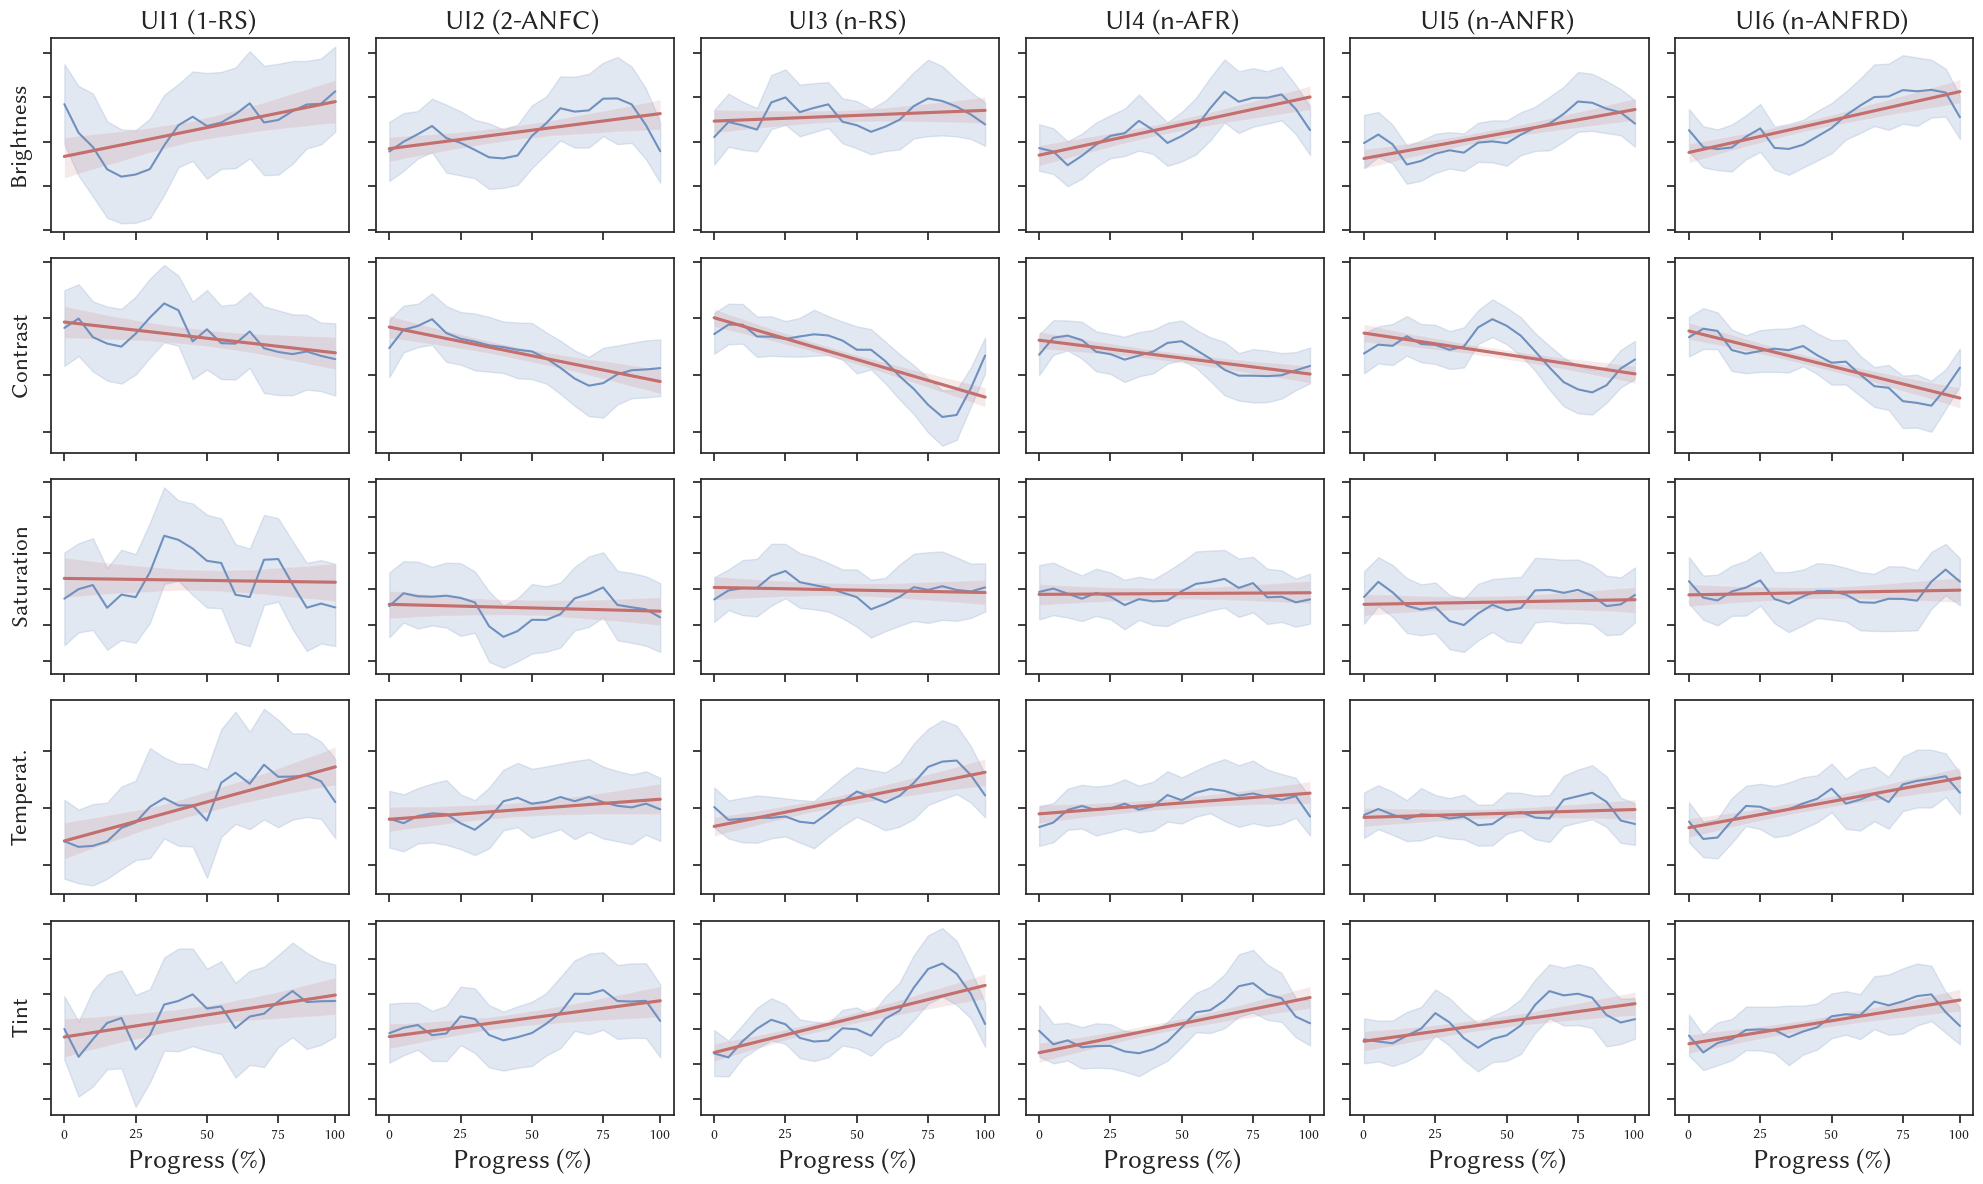

In [9]:
fig, axes = plt.subplots(5, 6, figsize=(20, 12))
colors = ['#6e90bf', '#c26f6d']
interfaces = ['pointwise', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie', 'listwise-ranking']
metrics = ['brightness', 'contrast', 'saturation', 'temperature', 'tint']
for j in range(5):
    for i in range(6):
        interface = 'pointwise'
        sns.lineplot(ax=axes[j][i], data=df_quality_progress[(df_quality_progress.interface == interfaces[i])], x='iteration', y=metrics[j], color=colors[0])
        sns.regplot(ax=axes[j][i], data=df_quality_progress[(df_quality_progress.interface == interfaces[i])], x='iteration', y=metrics[j], scatter=False, order=1, color=colors[1])

ymin, ymax = axes[0][0].get_ylim()
for j in range(6):
    yi, ya = axes[0][j].get_ylim()
    if ya > ymax:
        ymax = ya
    if yi < ymin:
        ymin = yi


for i in range(5):
    ymin, ymax = axes[i][0].get_ylim()
    for j in range(6):
        yi, ya = axes[i][j].get_ylim()
        if ya > ymax:
            ymax = ya
        if yi < ymin:
            ymin = yi

    for j in range(6):
        axes[i][j].set_ylim(ymin, ymax)
        axes[i][j].set_title('')
        axes[i][j].set_xlabel('')
        axes[i][j].set_ylabel('')
        axes[i][j].set_xticklabels([])
        # if j > 0:
        axes[i][j].set_yticklabels([])
        axes[i][j].legend().remove()

UIs = ['UI1 (1-RS)', 'UI2 (2-ANFC)', 'UI3 (n-RS)', 'UI4 (n-AFR)', 'UI5 (n-ANFR)', 'UI6 (n-ANFRD)']
for i in range(6):
    axes[0][i].set_title(UIs[i], fontsize=20)
metrics = ['Brightness', 'Contrast', 'Saturation', 'Temperat.', 'Tint']
for i in range(5):
    axes[i][0].set_ylabel(metrics[i], fontsize=17)

for i in range(6):
    axes[4][i].set_xticks([0, 5, 10, 15, 19])
    axes[4][i].set_xticklabels([0, int(500/20), int(1000/20), int(1500/20), 100])
    axes[4][i].set_xlabel('Progress (\%)', fontsize=20)

plt.tight_layout()
plt.savefig('figures/quality_image.pdf', bbox_inches='tight')

In [9]:
df_quality_progress.to_csv('processed/quality_progress_image.csv')